# 04 · Revenue drivers, done honestly

**Question:** what is associated with a customer generating more revenue? In particular, do fulfilment problems cost revenue?

### Why the v1 result (R² = 0.971) was misleading
- **Close to arithmetic:** revenue = number of orders × average order value. Predicting revenue from order count is bound to score highly.
- **Mechanical feature:** the number of unique products rises with the number of orders.
- **Tiny test set:** one 80/20 split of 89 customers means R² was measured on **18** customers.
- **Units:** unscaled coefficients are in different units (orders, days, £), so their sizes can't be ranked as "impact".
- The shipping-reliability coefficient (+£2,981 for going from 0% to 100% reliability) was smaller than the model's own error (£23k RMSE), yet it was reported as a finding.

In [1]:
import sys
from pathlib import Path

# make the src/ package importable from notebooks/ (no hard-coded C:\ paths)
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}" if abs(v) < 1 else f"{v:,.2f}")

from autosales.data import load_raw, build_order_lines, build_order_summary, build_customer_features
from autosales import kpis, segmentation, clustering, modelling, plots
%matplotlib inline

In [2]:
lines = build_order_lines(load_raw())
orders = build_order_summary(lines)
cust = build_customer_features(lines, orders)
frame = modelling.model_frame(cust)
print(f"{len(frame)} customers; {frame.had_order_at_risk_or_lost.sum()} had an order at risk or lost")
frame.head()

89 customers; 10 had an order at risk or lost


,customer_name,log_revenue,log_frequency,recency_days,had_order_at_risk_or_lost,frequency
0,"AV Stores, Co.",11.97,1.10,197,0,3
1,Alpha Cognac,11.16,1.10,65,0,3
2,Amica Models & Co.,11.45,0.6931,266,0,2
3,"Anna's Decorations, Ltd",11.94,1.39,84,0,4
4,Atelier graphique,10.09,1.10,189,0,3


## 1. Log–log regression with robust standard errors
On the log scale the coefficient on log(order count) is an **elasticity**: 1.0 means revenue rises in proportion to orders. HC3 standard errors stay valid even if errors are uneven across customers. Every coefficient comes with a 95% confidence interval.

In [3]:
res = modelling.run(cust)
res["ols_full"]

,term,coef,ci_low,ci_high,p_value,r2,n
0,const,10.19,9.77,10.61,0.0000,0.5147,89
1,log_frequency,1.06,0.8196,1.31,0.0000,0.5147,89
2,recency_days,0.0003,-0.0005,0.0011,0.4999,0.5147,89
3,had_order_at_risk_or_lost,0.0496,-0.1861,0.2854,0.6799,0.5147,89


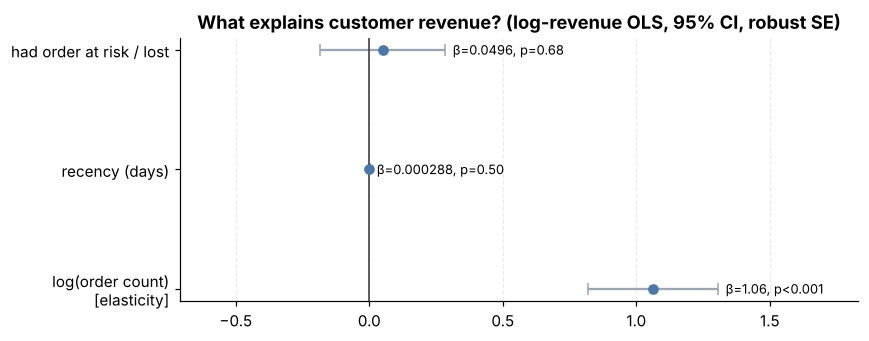

In [4]:
_ = plots.revenue_drivers(res["ols_full"])

## 2. Does adding recency and fulfilment issues predict better out of sample?
We use repeated 5-fold cross-validation (20 repeats = 100 train/test fits) rather than one split.

In [5]:
res["cv"]

,model,cv_r2_mean,cv_r2_std,n_fits
0,Baseline: order count only,0.4099,0.2775,100
1,Full: + recency + fulfilment issue,0.3887,0.2800,100


## 3. Sensitivity: drop the two very large accounts

In [6]:
res["ols_without_two_largest"]

,term,coef,ci_low,ci_high,p_value,r2,n
0,const,10.27,9.56,10.98,0.0000,0.3079,87
1,log_frequency,0.9921,0.4998,1.48,0.0001,0.3079,87
2,recency_days,0.0002,-0.0008,0.0013,0.6888,0.3079,87
3,had_order_at_risk_or_lost,0.0593,-0.1927,0.3113,0.6448,0.3079,87


## Conclusion (stated carefully)
- **Revenue is driven by order volume.** The elasticity is about 1.06 (95% CI 0.82–1.31), so revenue grows roughly in proportion to the number of orders, and average order value is similar across customers.
- **No evidence that fulfilment problems reduce customer revenue in this data.** The coefficient is close to zero (p ≈ 0.68), and adding it doesn't improve cross-validated R².
- **But "no evidence" is not "no effect".** Only 10 of 89 customers had an order at risk or lost, so the test has low power. Fulfilment still matters directly: £251k is at risk and £194k was lost.

**Business implication:** growth comes from more orders per account (frequency programmes, reorder prompts, cross-selling product lines), not from raising basket size. Fulfilment issues are worth fixing for the revenue directly involved; this data can't prove a longer-term retention effect.